Попытка №1

Начальная позиция агента: [5, 5]
Позиция кости: [3, 2]


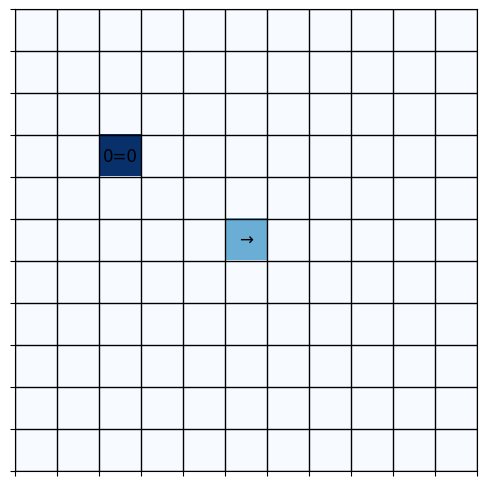

Шаг 1: Агент на [5, 4], Награда: -1


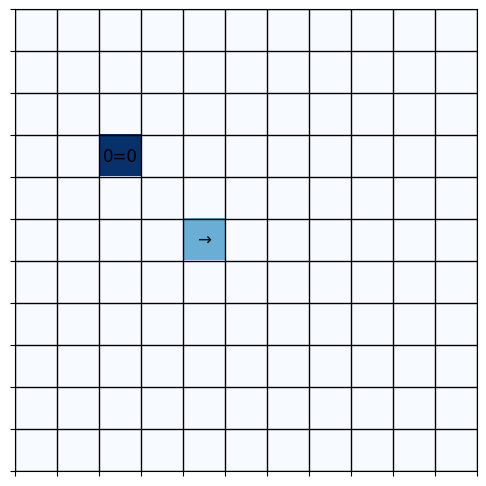

Шаг 2: Агент на [5, 3], Награда: -1


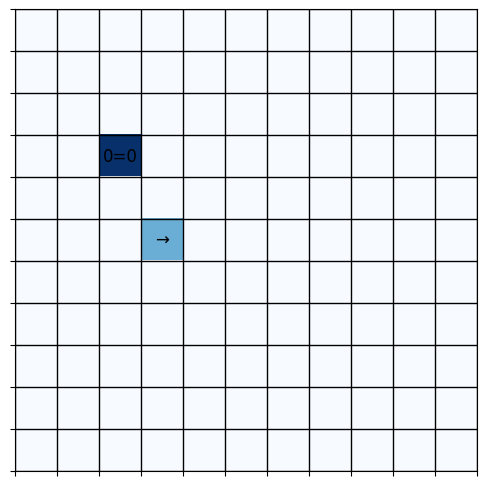

Шаг 3: Агент на [5, 4], Награда: -1


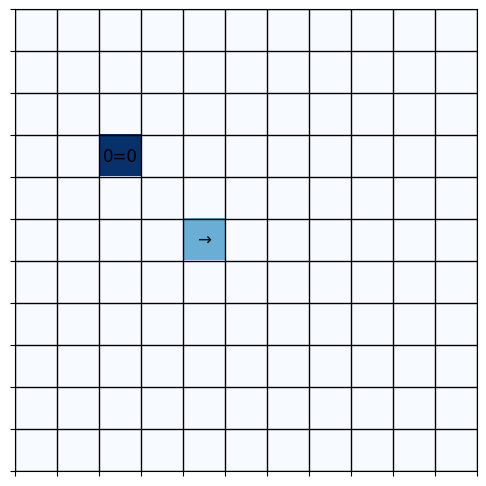

Шаг 4: Агент на [6, 4], Награда: -1


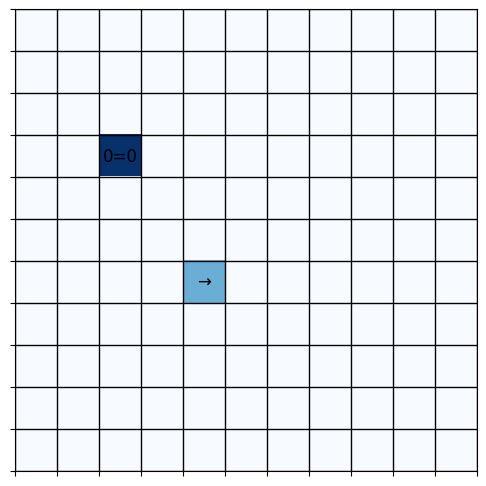

Шаг 5: Агент на [7, 4], Награда: -1


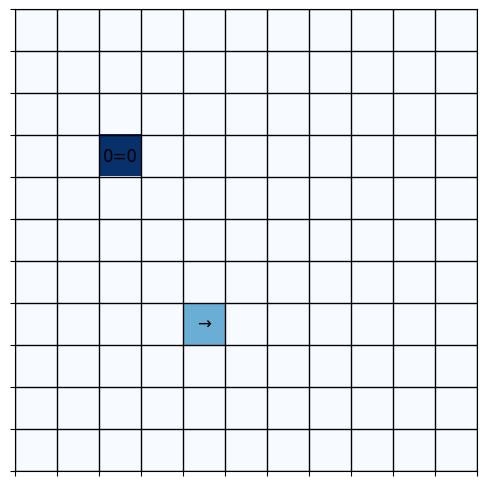

Шаг 6: Агент на [7, 5], Награда: -1


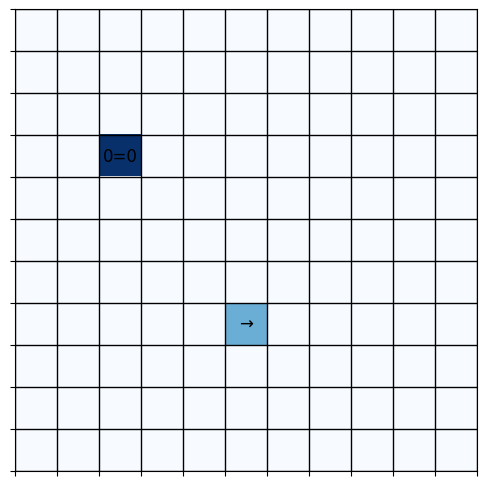

Шаг 7: Агент на [8, 5], Награда: -1


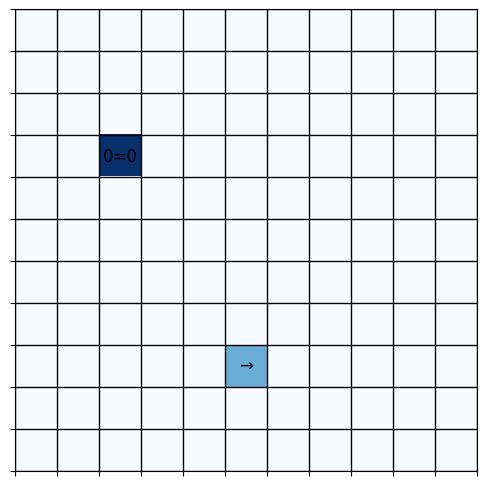

Шаг 8: Агент на [8, 4], Награда: -1


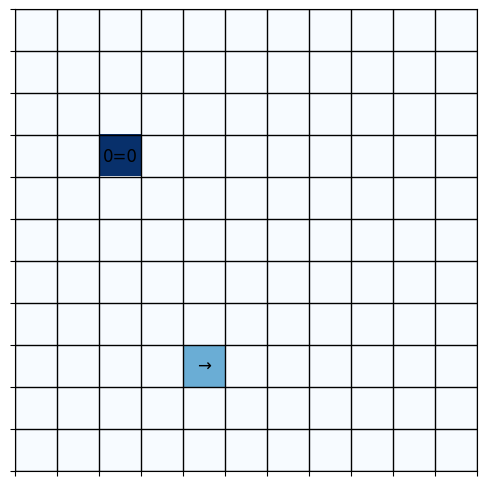

Шаг 9: Агент на [8, 5], Награда: -1


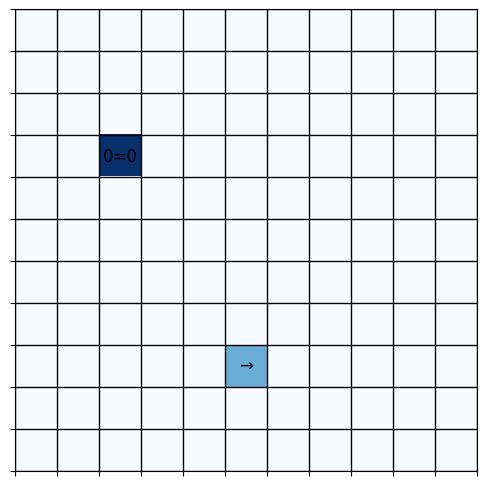

Шаг 10: Агент на [8, 6], Награда: -1


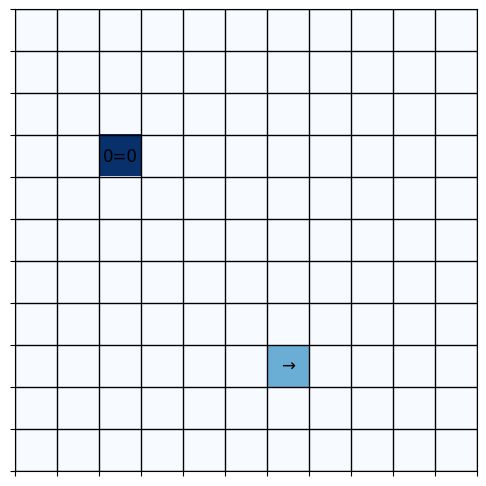

Шаг 11: Агент на [8, 5], Награда: -1


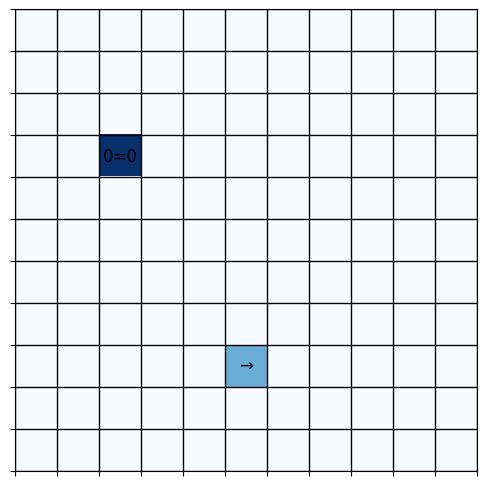

Шаг 12: Агент на [8, 4], Награда: -1


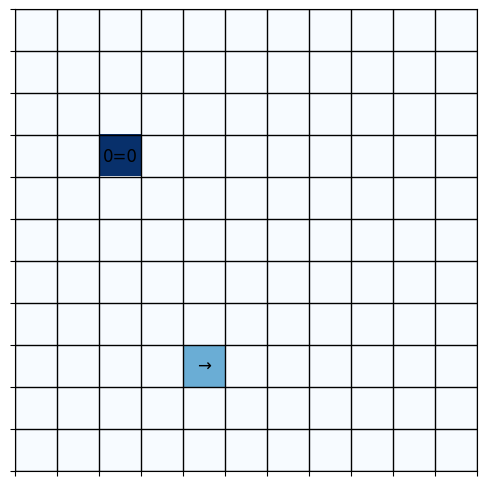

Шаг 13: Агент на [9, 4], Награда: -1


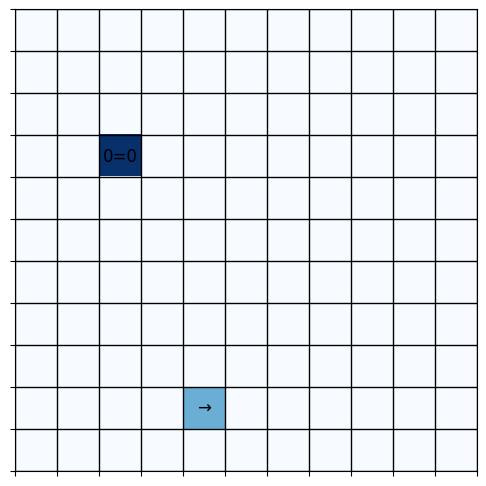

Шаг 14: Агент на [10, 4], Награда: -1


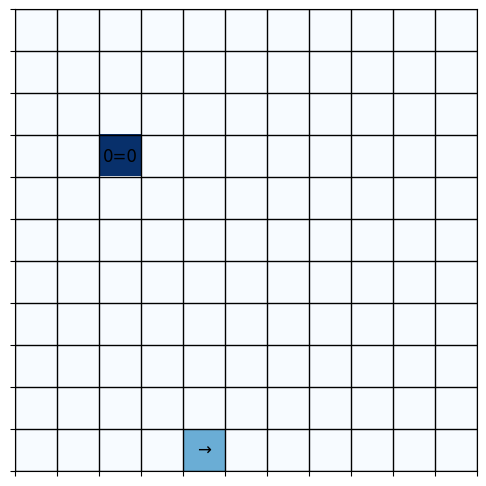

Шаг 15: Агент на [10, 4], Награда: -1


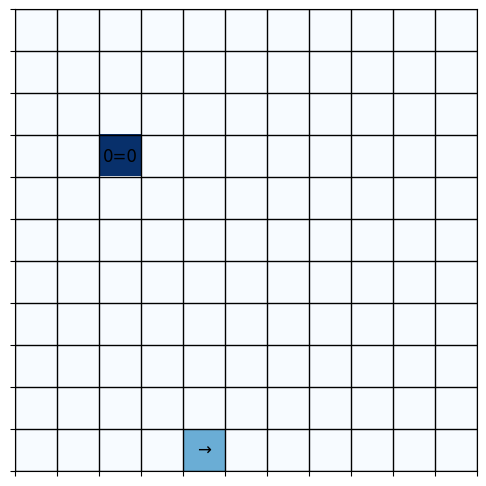

Шаг 16: Агент на [10, 5], Награда: -1


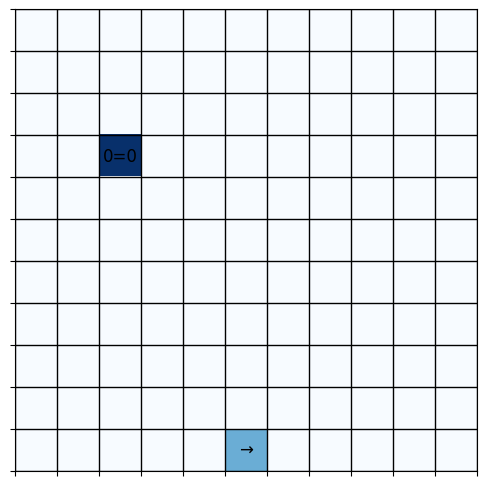

Шаг 17: Агент на [10, 6], Награда: -1


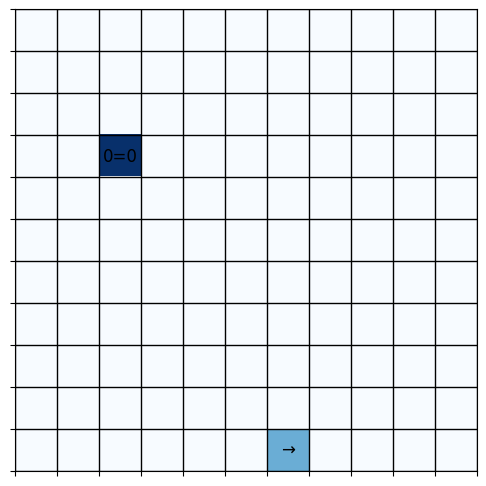

Шаг 18: Агент на [10, 6], Награда: -1


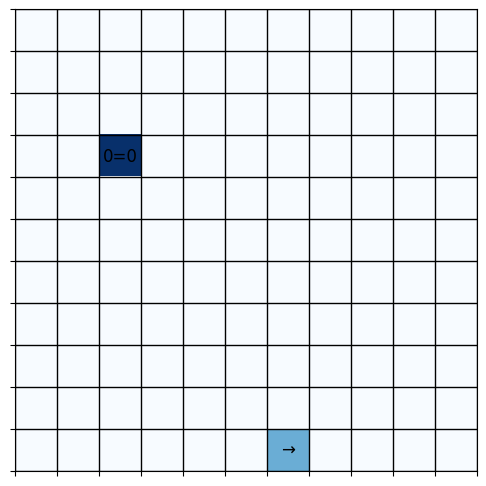

Шаг 19: Агент на [10, 5], Награда: -1


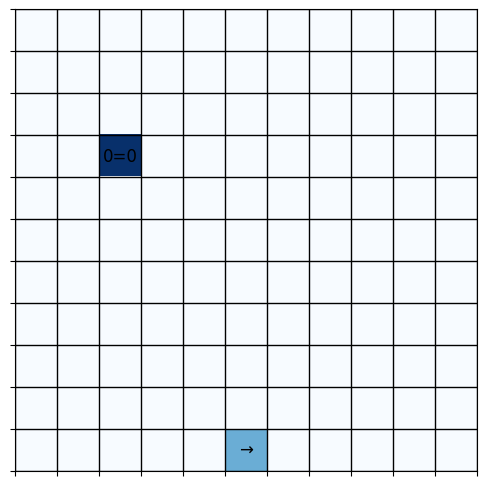

Шаг 20: Агент на [10, 4], Награда: -1


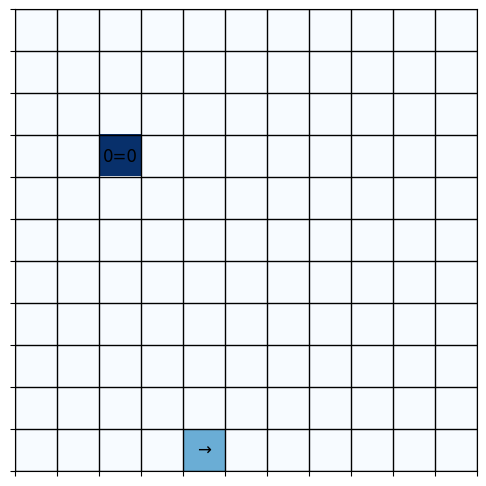

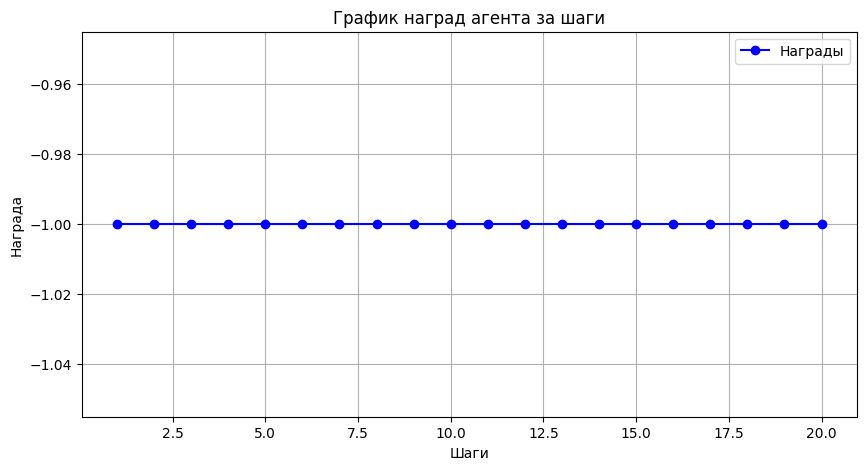

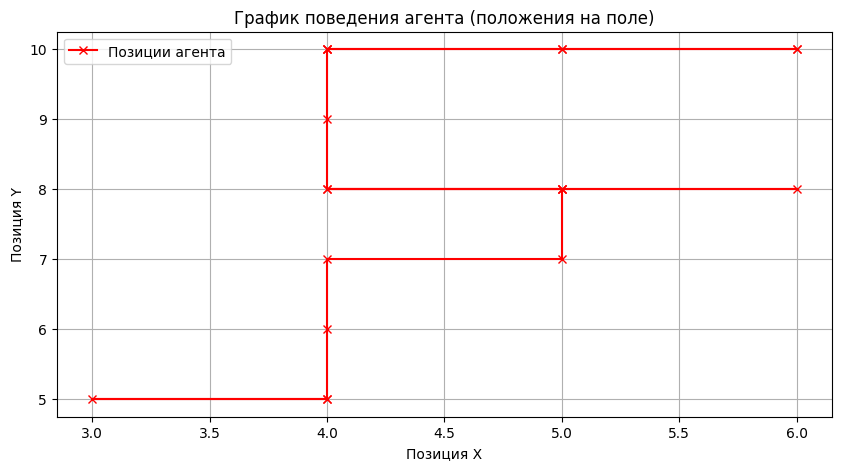

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Параметры
GRID_SIZE = 11
EPISODES = 1
STEPS_PER_EPISODE = 20

# Инициализация игрового поля
def init_grid():
    grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
    return grid

# Функция для отображения игрового поля
def plot_grid(agent_pos, bone_pos):
    grid = init_grid()

    # Помещаем агента и кость на поле
    grid[agent_pos[0], agent_pos[1]] = 1
    grid[bone_pos[0], bone_pos[1]] = 2

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=2)

    # Добавляем аннотации для агента и кости
    ax.text(agent_pos[1], agent_pos[0], "→", ha='center', va='center', color="black", fontsize=12)
    ax.text(bone_pos[1], bone_pos[0], "0=0", ha='center', va='center', color="black", fontsize=12)

    ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1))
    ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(which='both', color='black', linestyle='-', linewidth=1)

    plt.show()

# Функция для перемещения агента
def move_agent(agent_pos, action):
    if action == 1:  # Вправо
        if agent_pos[1] < GRID_SIZE - 1:
            agent_pos[1] += 1
    elif action == 2:  # Вниз
        if agent_pos[0] < GRID_SIZE - 1:
            agent_pos[0] += 1
    elif action == 3:  # Влево
        if agent_pos[1] > 0:
            agent_pos[1] -= 1
    return agent_pos

# Функция для расчета награды
def calculate_reward(agent_pos, bone_pos):
    if agent_pos == bone_pos:
        return 10  # Награда за сбор кости
    return -1  # Штраф за движение (за каждый шаг)

# Собираем статистику для графиков
reward_list = []
agent_positions = []

# Основной цикл игры
agent_pos = [5, 5]  # Начальная позиция агента в центре поля
bone_pos = [random.randint(0, GRID_SIZE-1), random.randint(0, GRID_SIZE-1)]  # Случайная позиция кости

# Убедимся, что начальная позиция кости не совпадает с позицией агента
while bone_pos == agent_pos:
    bone_pos = [random.randint(0, GRID_SIZE-1), random.randint(0, GRID_SIZE-1)]

print(f"Начальная позиция агента: {agent_pos}")
print(f"Позиция кости: {bone_pos}")

# Показать начальное состояние
plot_grid(agent_pos, bone_pos)

# Симуляция шагов агента
for step in range(STEPS_PER_EPISODE):
    # Случайное действие (для демонстрации) от 0 до 3
    action = random.choice([1, 2, 3])  # Действие 4 (вверх) недоступно

    # Перемещение агента
    agent_pos = move_agent(agent_pos, action)

    # Расчет награды
    reward = calculate_reward(agent_pos, bone_pos)
    reward_list.append(reward)
    agent_positions.append(agent_pos.copy())

    # Показать новое состояние поля после действия агента
    print(f"Шаг {step + 1}: Агент на {agent_pos}, Награда: {reward}")
    plot_grid(agent_pos, bone_pos)

    # Если агент нашел кость, изменим позицию кости
    if agent_pos == bone_pos:
        bone_pos = [random.randint(0, GRID_SIZE-1), random.randint(0, GRID_SIZE-1)]
        # Убедимся, что новая позиция кости не совпадает с позицией агента
        while bone_pos == agent_pos:
            bone_pos = [random.randint(0, GRID_SIZE-1), random.randint(0, GRID_SIZE-1)]
        print(f"Кость найдена! Новая позиция кости: {bone_pos}")

# Построение графиков

# График наград
plt.figure(figsize=(10, 5))
plt.plot(range(1, STEPS_PER_EPISODE + 1), reward_list, label="Награды", marker='o', color='blue')
plt.title("График наград агента за шаги")
plt.xlabel("Шаги")
plt.ylabel("Награда")
plt.grid(True)
plt.legend()
plt.show()

# График поведения агента (положение на поле)
agent_x = [pos[1] for pos in agent_positions]
agent_y = [pos[0] for pos in agent_positions]

plt.figure(figsize=(10, 5))
plt.plot(agent_x, agent_y, label="Позиции агента", marker='x', color='red')
plt.title("График поведения агента (положения на поле)")
plt.xlabel("Позиция X")
plt.ylabel("Позиция Y")
plt.grid(True)
plt.legend()
plt.show()

агент подходит к кости и
 или стоит на месте, вызывая команду 0 которая не распознаётся, или бегает
 вперёд-назад.

Попытка №2

... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... -0> ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... 0=0 ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...


... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... -0> ... ... ... ... ...
... ... ... ... ... ... 0=0 ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...
... ... ... ... ... ... ... ... ... ... ...


... ... ... ... ... ... ... 

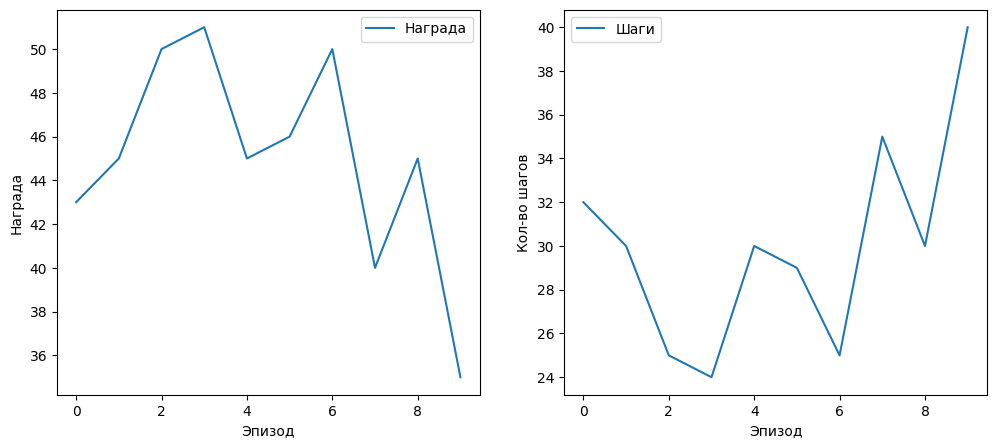

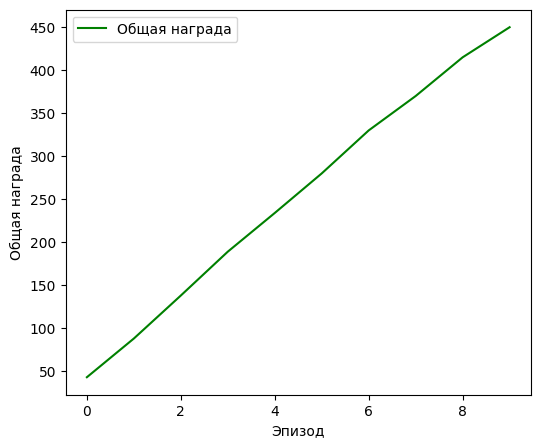

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
import time

# Константы
GRID_SIZE = 11
REWARD_MOVE = -1
REWARD_BONE = 10
REWARD_ALL_BONES = 30
PENALTY_BORDER = -50

# Функция создания игрового поля
def init_positions():
    agent_pos = [GRID_SIZE // 2, GRID_SIZE // 2]
    bone_pos = [np.random.randint(1, GRID_SIZE-1), np.random.randint(1, GRID_SIZE-1)]
    return agent_pos, bone_pos

# Визуализация поля
def print_grid(agent_pos, bone_pos):
    grid = np.full((GRID_SIZE, GRID_SIZE), '...', dtype='<U3')
    grid[agent_pos[0], agent_pos[1]] = '-0>'
    grid[bone_pos[0], bone_pos[1]] = '0=0'
    for row in grid:
        print(" ".join(row))
    print("\n")
    time.sleep(0.2)

# Определение награды
def calculate_reward(agent_pos, bone_pos, collected):
    if agent_pos == bone_pos:
        collected.append(bone_pos.copy())
        return REWARD_BONE if len(collected) < 5 else REWARD_ALL_BONES
    if agent_pos[0] < 0 or agent_pos[0] >= GRID_SIZE or agent_pos[1] < 0 or agent_pos[1] >= GRID_SIZE:
        return PENALTY_BORDER
    return REWARD_MOVE

# Генерация обучающих данных
X_train, y_train = [], []
for dx in range(-GRID_SIZE, GRID_SIZE):
    for dy in range(-GRID_SIZE, GRID_SIZE):
        X_train.append([dx, dy])
        if abs(dx) > abs(dy):
            y_train.append(0 if dx < 0 else 1)  # Влево (0), вправо (1)
        else:
            y_train.append(2 if dy < 0 else 3)  # Вверх (2), вниз (3)

# Обучение модели
model = MLPClassifier(hidden_layer_sizes=(25, 25), activation='tanh', max_iter=1000)
model.fit(X_train, y_train)

# Запуск игры
rewards, steps, total_rewards = [], [], []
for episode in range(10):  # Несколько эпизодов
    agent_pos, bone_pos = init_positions()
    collected = []
    total_reward, step = 0, 0

    while len(collected) < 5:
        print_grid(agent_pos, bone_pos)
        dx, dy = bone_pos[0] - agent_pos[0], bone_pos[1] - agent_pos[1]
        move = model.predict([[dx, dy]])[0]

        if move == 0:
            agent_pos[0] -= 1  # Влево
        elif move == 1:
            agent_pos[0] += 1  # Вправо
        elif move == 2:
            agent_pos[1] -= 1  # Вверх
        elif move == 3:
            agent_pos[1] += 1  # Вниз

        reward = calculate_reward(agent_pos, bone_pos, collected)
        total_reward += reward
        step += 1
        if agent_pos == bone_pos:
            bone_pos = [np.random.randint(1, GRID_SIZE-1), np.random.randint(1, GRID_SIZE-1)]

    rewards.append(total_reward)
    steps.append(step)
    total_rewards.append(np.sum(rewards))  # Подсчёт общей награды на каждом шаге
    print(f"Эпизод {episode+1}: награда = {total_reward}, шаги = {step}, общая награда = {total_rewards[-1]}")

# Графики
plt.figure(figsize=(12, 5))

# Награды
plt.subplot(1, 2, 1)
plt.plot(rewards, label='Награда')
plt.xlabel('Эпизод')
plt.ylabel('Награда')
plt.legend()

# Шаги
plt.subplot(1, 2, 2)
plt.plot(steps, label='Шаги')
plt.xlabel('Эпизод')
plt.ylabel('Кол-во шагов')
plt.legend()

# Общая награда
plt.figure(figsize=(6, 5))
plt.plot(total_rewards, label='Общая награда', color='g')
plt.xlabel('Эпизод')
plt.ylabel('Общая награда')
plt.legend()

plt.show()

Попытка №3

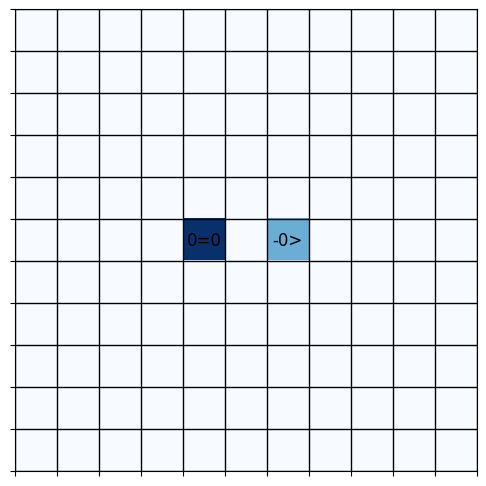

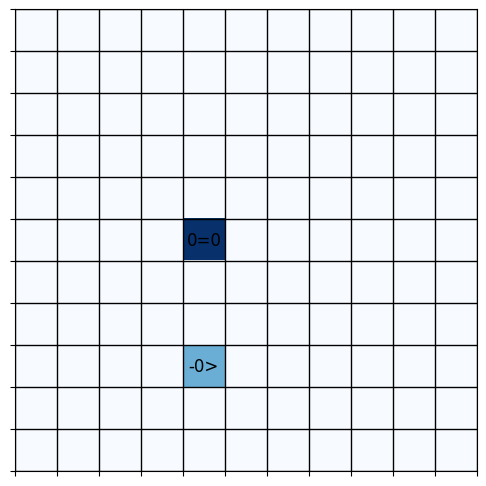

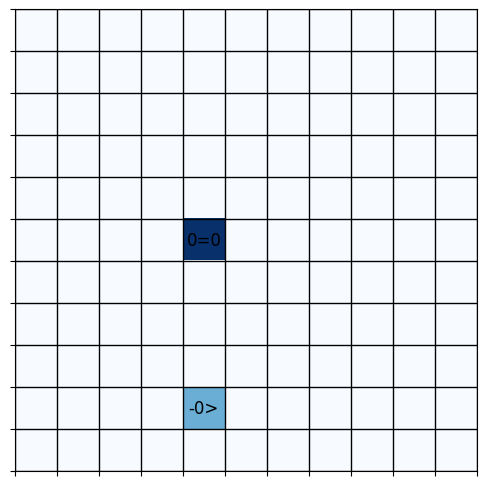

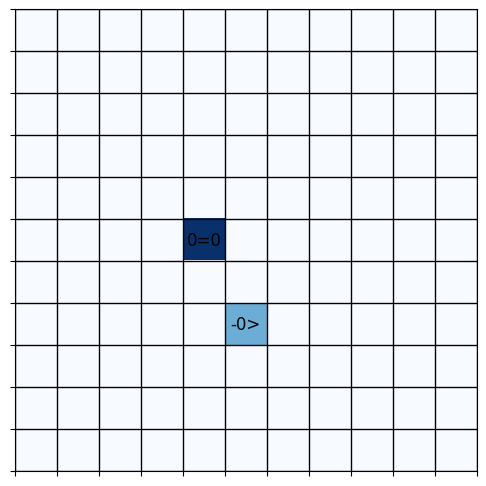

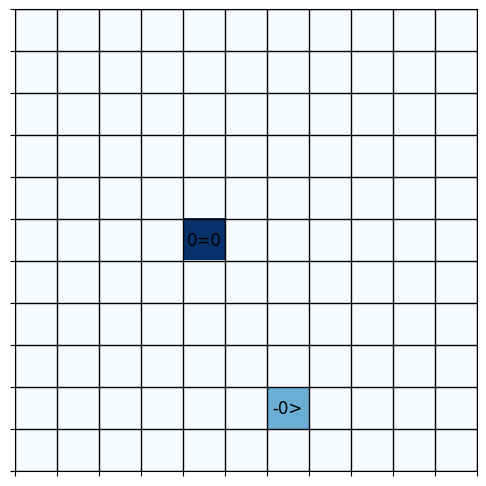

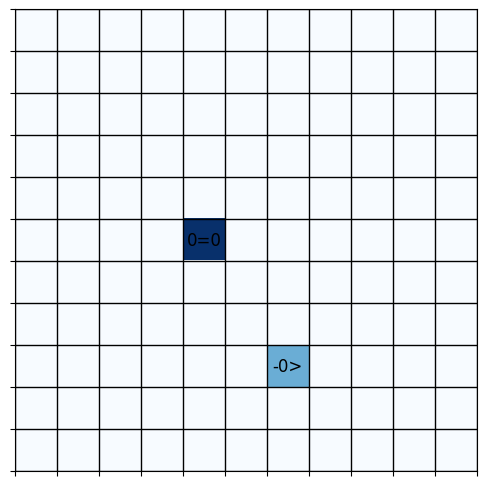

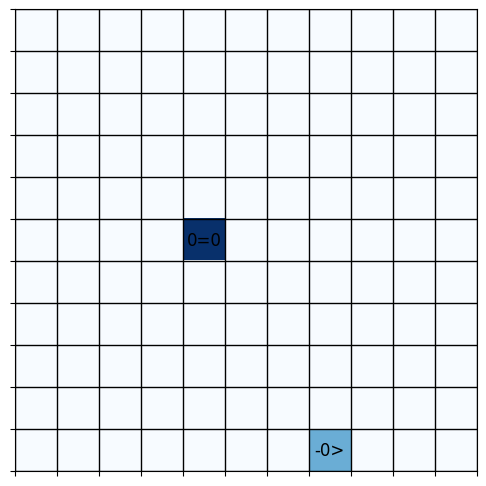

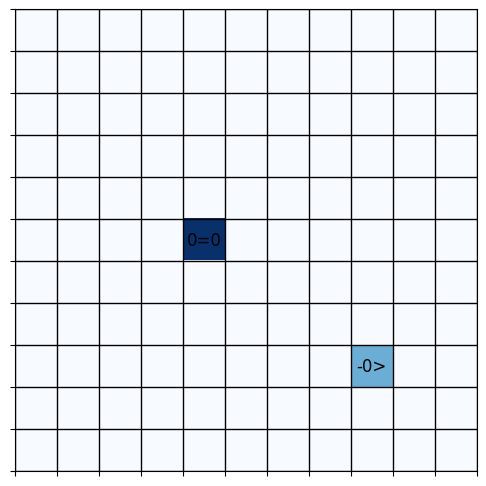

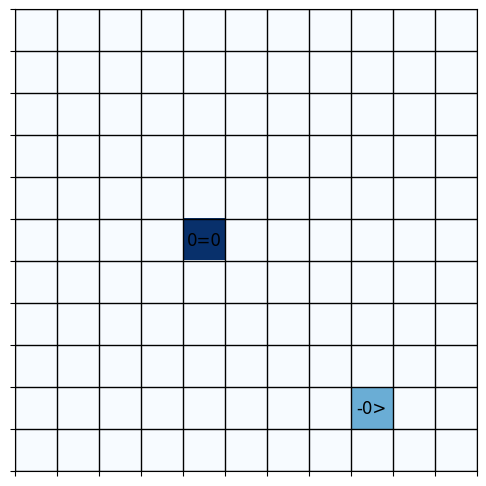

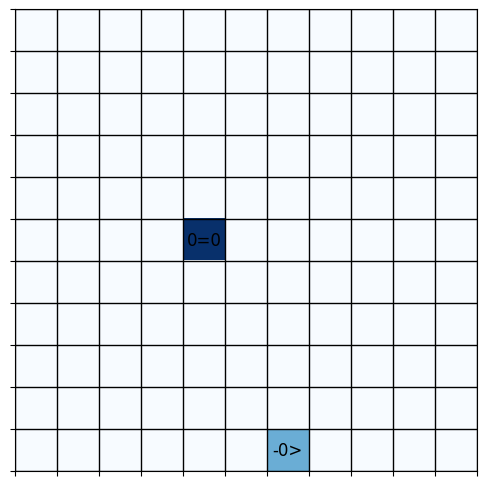

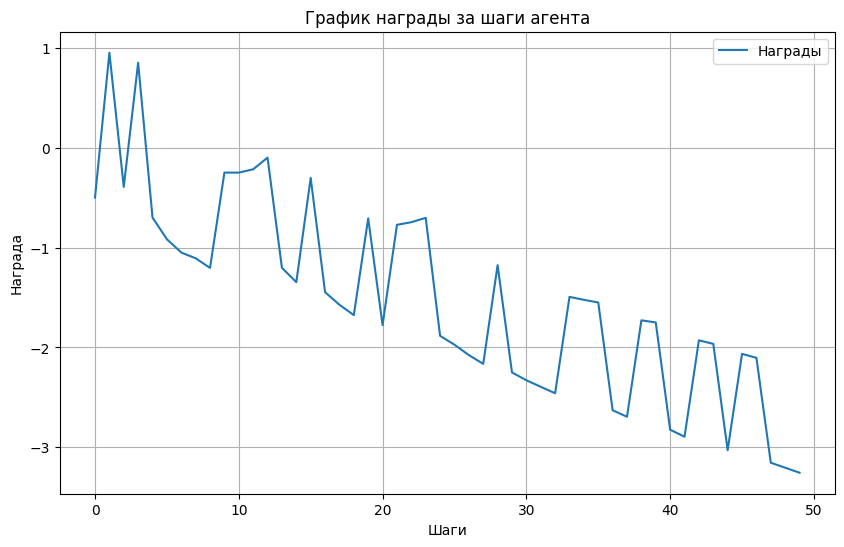

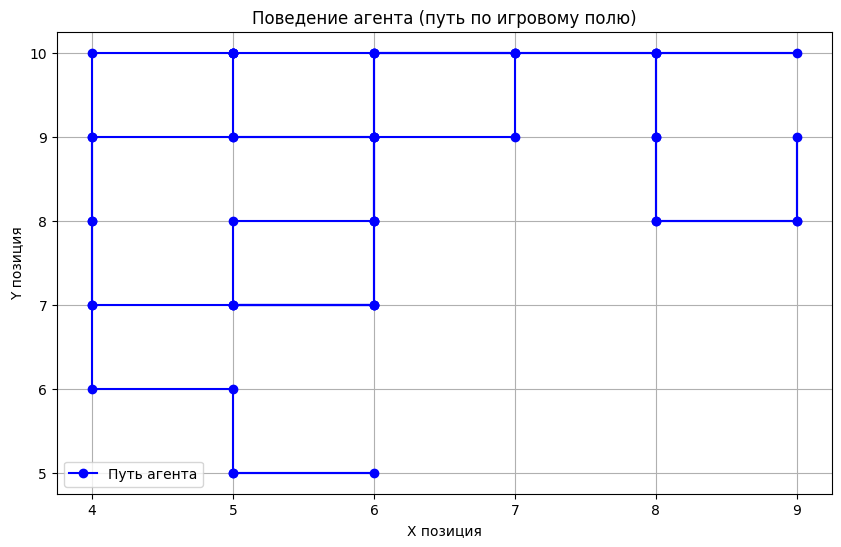

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Параметры
GRID_SIZE = 11
EPISODES = 1
STEPS_PER_EPISODE = 50
TIME_PENALTY_RATE = 0.05

# Инициализация игрового поля
def init_grid():
    grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
    return grid

# Функция для отображения игрового поля
def plot_grid(agent_pos, bone_pos):
    grid = init_grid()

    # Помещаем агента и кость на поле
    grid[agent_pos[0], agent_pos[1]] = 1
    grid[bone_pos[0], bone_pos[1]] = 2

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=2)

    # Добавляем аннотации для агента и кости
    ax.text(agent_pos[1], agent_pos[0], "-0>", ha='center', va='center', color="black", fontsize=12)
    ax.text(bone_pos[1], bone_pos[0], "0=0", ha='center', va='center', color="black", fontsize=12)

    ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1))
    ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(which='both', color='black', linestyle='-', linewidth=1)

    plt.show()

# Функция для вычисления награды за приближение
def calculate_reward(agent_pos, bone_pos, old_dist, time_steps):
    new_dist = np.linalg.norm(np.array(agent_pos) - np.array(bone_pos))

    # Награда за приближение
    if new_dist < old_dist:
        reward = 1 / new_dist
    else:
        reward = -(1 - 1 / new_dist)

    # Штраф за время
    reward -= (time_steps * TIME_PENALTY_RATE)

    return reward, new_dist

# Функция для перемещения агента
def move_agent(agent_pos, action):
    if action == 1:  # Вправо
        if agent_pos[1] < GRID_SIZE - 1:
            agent_pos[1] += 1
    elif action == 2:  # Вниз
        if agent_pos[0] < GRID_SIZE - 1:
            agent_pos[0] += 1
    elif action == 3:  # Влево
        if agent_pos[1] > 0:
            agent_pos[1] -= 1
    elif action == 4:  # Вверх
        if agent_pos[0] > 0:
            agent_pos[0] -= 1
    return agent_pos

# Симуляция одного эпизода
def simulate_episode():
    agent_pos = [5, 5]  # Начальная позиция агента в центре поля
    bone_pos = [random.randint(0, GRID_SIZE-1), random.randint(0, GRID_SIZE-1)]  # Случайная позиция кости

    old_dist = np.linalg.norm(np.array(agent_pos) - np.array(bone_pos))  # Начальное расстояние до кости
    rewards = []
    agent_positions = [agent_pos.copy()]

    # Симуляция шагов
    for time_step in range(STEPS_PER_EPISODE):
        action = random.choice([1, 2, 3, 4])  # Случайное действие для демонстрации

        # Перемещение агента
        agent_pos = move_agent(agent_pos, action)

        # Вычисление награды
        reward, old_dist = calculate_reward(agent_pos, bone_pos, old_dist, time_step)
        rewards.append(reward)
        agent_positions.append(agent_pos.copy())

        # Отображение поля после шага
        if time_step % 5 == 0:  # Показать поле каждые 5 шагов
            plot_grid(agent_pos, bone_pos)

    return rewards, agent_positions

# Основной цикл
episode_rewards, episode_positions = simulate_episode()

# График награды
plt.figure(figsize=(10, 6))
plt.plot(range(len(episode_rewards)), episode_rewards, label="Награды")
plt.xlabel('Шаги')
plt.ylabel('Награда')
plt.title('График награды за шаги агента')
plt.grid(True)
plt.legend()
plt.show()

# График поведения агента (позиции агента на поле)
x_pos = [pos[1] for pos in episode_positions]
y_pos = [pos[0] for pos in episode_positions]

plt.figure(figsize=(10, 6))
plt.plot(x_pos, y_pos, marker='o', linestyle='-', color='b', label="Путь агента")
plt.xlabel('X позиция')
plt.ylabel('Y позиция')
plt.title('Поведение агента (путь по игровому полю)')
plt.grid(True)
plt.legend()
plt.show()